# Data discrepancies in the PDP mock data

- The two mock Analysis-Ready Files contain the data issues documented below.
- The data is synthetic. These results describe mock records and provide no evidence about real students or institutions.
- **Data files:**
  - `data/raw/pdp_cohort_data.csv`: one row per student and cohort; 10,313 rows.
  - `data/raw/pdp_course_data.csv`: one row per class or term; 100,951 rows.
  - Column meanings are in `data/dictionaries/`.
  - All corrections use copies of the data. The raw files remain unchanged.
- **Issue numbering:**
  - **1–15:** match the “Mock data bugs” doc.
  - **N1–N22:** newer findings from the 2026-10-30 audit.
  - **S1–S6:** smaller items.
  - Related issues share a heading that lists their identifiers.


In [18]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
RAW = ROOT / "data" / "raw"
# Load values as strings to preserve Course_Prefix = NA and column-specific missing markers.
cohort = pd.read_csv(RAW / "pdp_cohort_data.csv", dtype=str, keep_default_na=False)
course = pd.read_csv(RAW / "pdp_course_data.csv", dtype=str, keep_default_na=False)
print(f"cohort file: {cohort.shape[0]:,} rows x {cohort.shape[1]} columns")
print(f"course file: {course.shape[0]:,} rows x {course.shape[1]} columns")

KEY = ["Student_GUID", "Cohort"]  # one cohort-file row; the course file's link to it
CUTOFF = 2025  # last academic year the files cover (2025-26): a working assumption, see issue 2
TERM_ORDER = {"FALL": 0, "WINTER": 1, "SPRING": 2, "SUMMER": 3}  # PDP order within an academic year
pd.set_option("display.max_columns", 12, "display.max_colwidth", 40)


def num(s):
    """Numbers as floats; the files' null markers (blank, '.', 'NA', 'UK') become NaN."""
    return pd.to_numeric(s.mask(s.isin(["", ".", "NA", "UK"])), errors="coerce")


def year(s):
    """First year of a 'YYYY-YY' academic year: '2024-25' -> 2024."""
    return pd.to_numeric(s.str[:4], errors="coerce")


def in_rows(rows, df=cohort):
    """True for each row of df whose (Student_GUID, Cohort) appears in rows."""
    return df.set_index(KEY).index.isin(rows.set_index(KEY).index)


def show(label, mask, df, cols, n=3):
    """Print how many rows match, and return the first n as examples."""
    print(f"{label}: {int(mask.sum()):,}")
    return df.loc[mask, cols].head(n)


def before_after(label, before, after):
    print(f"{label}: {int(before):,} before -> {int(after):,} after")


# Store derived values as Series aligned with the course index; preserve the source columns.
course_year = year(course.Academic_Year)
year_n = course_year - year(course.Cohort) + 1  # 1 = the row is in the student's first academic year
has_class = course.Course_Prefix != ""  # rows without a class record a term elsewhere, or nothing
classes = course[has_class]
print(f"class rows: {len(classes):,}")

cohort file: 10,313 rows x 85 columns
course file: 100,951 rows x 35 columns
class rows: 83,196


In [17]:
import sys
if str(ROOT / "notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "notebooks"))
import plotting  

## Cohort file

#### 1. First_Gen codes and NASPAFirstGeneration differences

The dictionary defines First_Gen through parents' education: N means no parent attended college; P, C, A, B and E describe attendance or credentials. The file contains Y and N. Interpreting these as yes/no first-generation status reverses the documented meaning of N and produces differences from NASPAFirstGeneration. The comparison depends on both fields using the same definition.

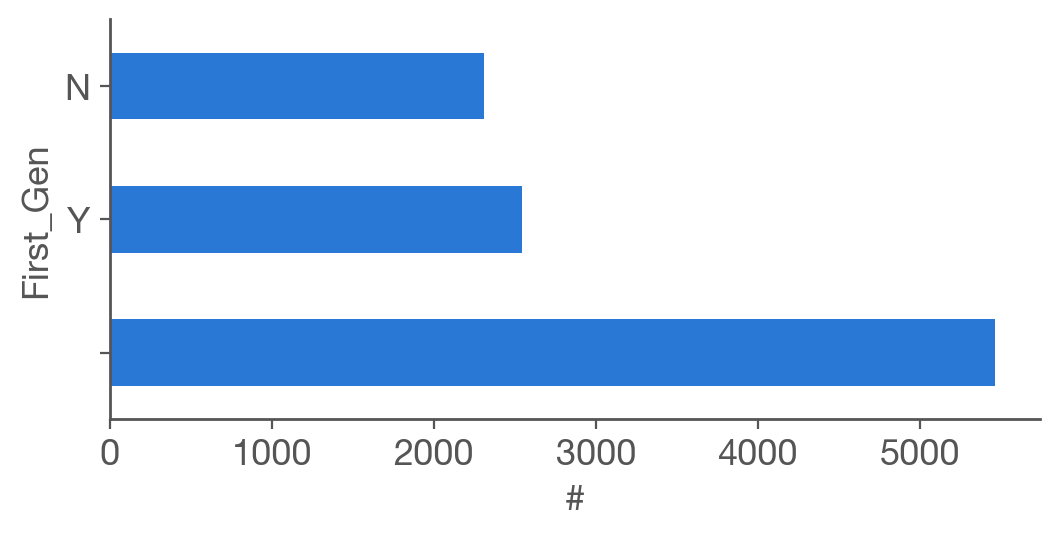

In [78]:
ax = cohort.First_Gen.value_counts(dropna=False).plot.barh(color="#2a78d6", figsize=(6, 2.5))
ax.set_xlabel("#");

In [19]:
print(cohort.First_Gen.replace("", "(blank)").value_counts().to_dict())
both = cohort[(cohort.First_Gen != "") & (cohort.NASPAFirstGeneration != "-1")]
agree = ((both.First_Gen == "N") & (both.NASPAFirstGeneration == "0")) | (
    (both.First_Gen == "Y") & both.NASPAFirstGeneration.isin(["1", "2"])
)
print(f"known in both columns: {len(both)}, agree: {agree.sum()}")
pd.crosstab(both.First_Gen, both.NASPAFirstGeneration)

{'(blank)': 5462, 'Y': 2543, 'N': 2308}
known in both columns: 127, agree: 40


NASPAFirstGeneration,0,1,2
First_Gen,,,
N,22,20,5
Y,62,0,18


> **Recommended:** Confirm the Y/N definition with the data provider. Preserve both fields and flag differences from NASPAFirstGeneration until their definitions are clear.


In [20]:
# Preserve both fields and flag differences under the assumed Y/N definition.
fixed = cohort.copy()
fixed["first_gen_conflict"] = False
fixed.loc[both.index[~agree], "first_gen_conflict"] = True
before_after("contradicting rows without a flag", (~agree).sum(), (~agree & ~fixed.loc[both.index, "first_gen_conflict"]).sum())
print("flagged:", fixed.first_gen_conflict.sum())

contradicting rows without a flag: 87 before -> 0 after
flagged: 87


#### 2. Zero credits for unobserved years 3 and 4

Zero credits can imply that a student attempted no coursework during an observed year. For students who started in 2024-25, years 3 and 4 fall after the assumed 2025-26 cutoff. Including those zeros in retention analysis can misclassify students as having stopped out. Course records dated 2026-27 require confirmation of the cutoff.

In [21]:
for n in (3, 4):
    future = year(cohort.Cohort) + n - 1 > CUTOFF
    values = cohort.loc[future, f"Number_of_Credits_Attempted_Yr_{n}"].value_counts().to_dict()
    print(f"year {n} after 2025-26: {future.sum():,} students, Number_of_Credits_Attempted_Yr_{n} = {values}")
print("course rows dated after 2025-26:", (course_year > CUTOFF).sum())

year 3 after 2025-26: 2,612 students, Number_of_Credits_Attempted_Yr_3 = {'0': 2520, '.': 92}
year 4 after 2025-26: 5,192 students, Number_of_Credits_Attempted_Yr_4 = {'0': 5039, '.': 153}
course rows dated after 2025-26: 9


> **Recommended:** Replace year-3 and year-4 credit zeros with blanks when those years fall after the assumed 2025-26 cutoff. These years are not yet observed; confirm the cutoff before applying this rule.


In [22]:
def future_zeros(df):
    return sum(
        ((year(df.Cohort) + n - 1 > CUTOFF) & (df[f"Number_of_Credits_{kind}_Yr_{n}"] == "0")).sum()
        for n in (3, 4) for kind in ("Attempted", "Earned")
    )

fixed = cohort.copy()
for n in (3, 4):
    future = year(fixed.Cohort) + n - 1 > CUTOFF
    for kind in ("Attempted", "Earned"):
        col = f"Number_of_Credits_{kind}_Yr_{n}"
        fixed.loc[future & (fixed[col] == "0"), col] = ""  # not observed yet, so no value
before_after("future-year zeros (4 columns)", future_zeros(cohort), future_zeros(fixed))
# Loader rule: data_fixes.yaml `future_credit_years_are_blank`, using the assumed 2025-26 cutoff.

future-year zeros (4 columns): 15,118 before -> 0 after


#### 6. Unknown ethnicity with a reported race

Most students with a reported race, including White, Black and Asian, have Ethnicity = UK. Their Hispanic ethnicity remains unknown. Counts based on Ethnicity = N exclude these students.

In [23]:
SPECIFIC = ["White", "Black or African American", "Asian", "American Indian or Alaska",
            "Native Hawaiian or Other", "Two or More Races"]
eth_uk = cohort.Race.isin(SPECIFIC) & (cohort.Ethnicity == "UK")
print("students:", cohort.loc[eth_uk, "Student_GUID"].nunique())
show("cohort rows with a specific race and Ethnicity = UK", eth_uk, cohort, ["Student_GUID", "Race", "Ethnicity"])

students: 5857
cohort rows with a specific race and Ethnicity = UK: 5,859


,Student_GUID,Race,Ethnicity
0,004564B3B004E0B0E06349C8C70AB3EC,Black or African American,UK
1,006F3FF4E1F908EFE0535964C70A009A,Black or African American,UK
2,00A0A4D90DC29305E06349C8C70A4573,Black or African American,UK


> **Recommended:** Preserve UK and flag these rows for clarification from Achieving the Dream. Group them under unknown ethnicity in analyses.


In [24]:
# Preserve unknown ethnicity and flag records that also include a specific race.
fixed = cohort.copy()
fixed["ethnicity_uk_with_race"] = eth_uk
before_after("unflagged rows", eth_uk.sum(), (eth_uk & ~fixed.ethnicity_uk_with_race).sum())

unflagged rows: 5,859 before -> 0 after


#### N9. Blank ethnicity and Hispanic nonresident aliens

The dictionary lists H, N and UK for Ethnicity; the files also contain blanks. Nonresident alien with Ethnicity = H can be valid. IPEDS-style reporting groups nonresident aliens separately from domestic race and ethnicity categories.

In [25]:
print("Nonresident alien with Ethnicity = H:", ((cohort.Race == "Nonresident alien") & (cohort.Ethnicity == "H")).sum())
print("Ethnicity blank, course rows:", (course.Ethnicity == "").sum())
show("Ethnicity blank, cohort rows", cohort.Ethnicity == "", cohort, ["Student_GUID", "Race", "Ethnicity"])

Nonresident alien with Ethnicity = H: 83
Ethnicity blank, course rows: 79
Ethnicity blank, cohort rows: 4


,Student_GUID,Race,Ethnicity
1245,0F16A2DF86977339E0634F0F210AD64E,Unknown,
9457,EAF01F50F91F3B67E05349C8C70A067C,Unknown,
9458,EAF01F50F9343B67E05349C8C70A067C,Unknown,


> **Recommended:** Normalize blank Ethnicity to UK (unknown). Preserve Nonresident alien with Ethnicity = H, since that combination may be valid.


In [41]:
# Replace blank ethnicity with UK; preserve the potentially valid Nonresident alien + H combination.
fixed_co, fixed_cr = cohort.copy(), course.copy()
for df in (fixed_co, fixed_cr):
    df["Ethnicity"] = df.Ethnicity.replace("", "UK")
before_after("blank Ethnicity (both files)", (cohort.Ethnicity == "").sum() + (course.Ethnicity == "").sum(),
             (fixed_co.Ethnicity == "").sum() + (fixed_cr.Ethnicity == "").sum())

blank Ethnicity (both files): 83 before -> 0 after


#### 8. Time_to_Credential above the cohort-based limit

The 2021-22 cohort has five academic years through 2025-26. Longer durations require an earlier enrollment date or a correction. Re-admission, dual enrollment or summer enrollment may explain an earlier start. UK in Dual_and_Summer_Enrollment leaves that history unknown.

students with a Time_to_Credential: 1,977, max 27.7
over the limit with no earlier-enrollment explanation: 55


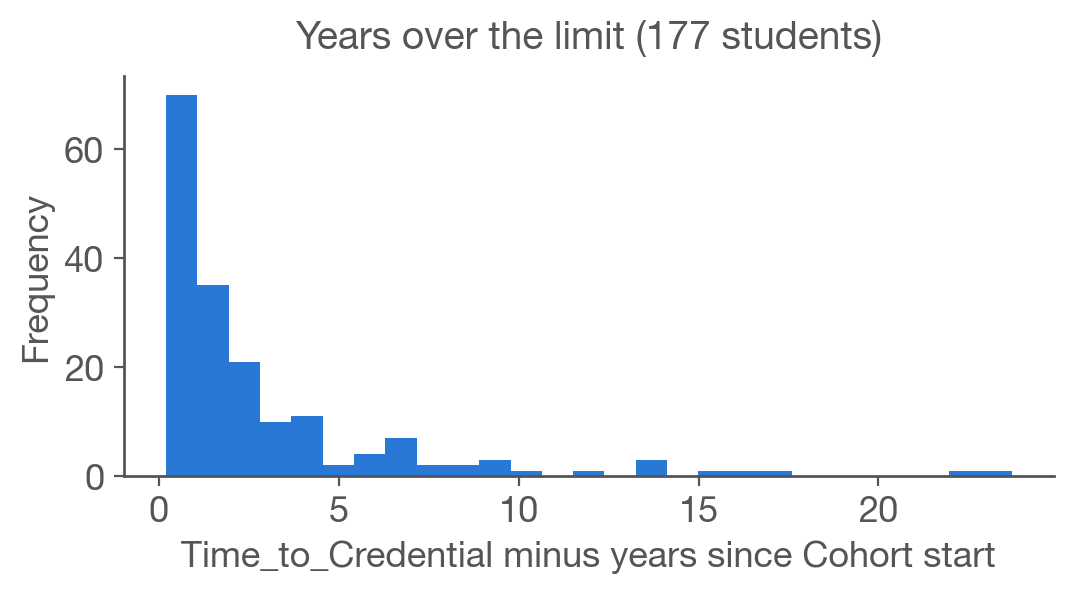

Time_to_Credential over the limit: 177


,Student_GUID,Cohort,Enrollment_Type,Dual_and_Summer_Enrollment,Time_to_Credential
50,0258E094348116D8E0531B64C70A723D,2022-23,First-Time,UK,4.6
77,0338137D4B6B1ACEE0531B64C70A3620,2021-22,First-Time,UK,8.8
728,05E28CCE655836ACE0531B64C70A0492,2021-22,Re-admit,UK,10.7


In [42]:
ttc = num(cohort.Time_to_Credential)
limit = CUTOFF + 1 - year(cohort.Cohort)
over = ttc > limit
impossible = over & cohort.Enrollment_Type.isin(["First-Time", "Transfer-In"]) & (cohort.Dual_and_Summer_Enrollment == "UK")
print(f"students with a Time_to_Credential: {ttc.notna().sum():,}, max {ttc.max()}")
print("over the limit with no earlier-enrollment explanation:", impossible.sum())
(ttc - limit)[over].plot.hist(bins=27, color="#2a78d6", figsize=(6, 2.5), title=f"Years over the limit ({over.sum()} students)")
plt.xlabel("Time_to_Credential minus years since Cohort start")
plt.show()
show("Time_to_Credential over the limit", over, cohort, ["Student_GUID", "Cohort", "Enrollment_Type", "Dual_and_Summer_Enrollment", "Time_to_Credential"])

> **Recommended:** Preserve Time_to_Credential and flag values above the cohort-based limit. Identify records with no known explanation separately. UK in Dual_and_Summer_Enrollment leaves an earlier start possible.


In [28]:
# Preserve durations and flag those above the cohort-based limit.
# UK leaves earlier enrollment possible; distinguish records with no known explanation.
fixed = cohort.copy()
fixed["ttc_over_limit"] = np.select([impossible, over], ["no known explanation", "may be real"], "")
print(fixed.ttc_over_limit.value_counts().to_dict())
before_after("unflagged rows over the limit", over.sum(), (over & (fixed.ttc_over_limit == "")).sum())

{'': 10136, 'may be real': 122, 'no known explanation': 55}
unflagged rows over the limit: 177 before -> 0 after


#### N16 + S1. Time_to_Credential vs the first-credential year

Time_to_Credential exceeds the first-credential year by more than a year for the N16 records. For the S1 records, students have a reported credential and a missing duration, represented by a dot.

In [29]:
first_cred = pd.concat([num(cohort.First_Year_to_A_or_C_at_cohort), num(cohort.First_Year_to_Bachelors_at_coh)], axis=1)
first_cred = first_cred.replace(0, np.nan).min(axis=1)  # 0 = no credential
too_long = ttc > first_cred + 1
missing_ttc = (cohort.Time_to_Credential == ".") & first_cred.notna()
print("S1. Time_to_Credential is '.' despite a credential:", missing_ttc.sum())
show("N16. Time_to_Credential > first-credential year + 1", too_long, cohort.assign(first_cred_year=first_cred),
     ["Student_GUID", "Cohort", "first_cred_year", "Time_to_Credential"])

S1. Time_to_Credential is '.' despite a credential: 56
N16. Time_to_Credential > first-credential year + 1: 259


,Student_GUID,Cohort,first_cred_year,Time_to_Credential
50,0258E094348116D8E0531B64C70A723D,2022-23,1.0,4.6
77,0338137D4B6B1ACEE0531B64C70A3620,2021-22,2.0,8.8
256,04D06C41A99E5B96E0634F0F210A91F5,2023-24,1.0,2.6


> **Recommended:** Flag durations above the first-credential year and missing durations for students with a credential. Calculating a replacement duration requires enrollment and award dates.


In [13]:
# Flag excessive and missing durations; replacement values require enrollment and award dates.
fixed = cohort.copy()
fixed["ttc_vs_credential_year"] = np.select([too_long, missing_ttc], ["too long", "missing"], "")
print(fixed.ttc_vs_credential_year.value_counts().to_dict())
before_after("unflagged rows", too_long.sum() + missing_ttc.sum(), ((too_long | missing_ttc) & (fixed.ttc_vs_credential_year == "")).sum())

{'': 9998, 'too long': 259, 'missing': 56}
unflagged rows: 315 before -> 0 after


#### 15 + J1–J3. Multiple cohorts per student and join checks

Two Student_GUID values occur in two cohorts each. Joining the files on Student_GUID alone duplicates those students' course rows. Joining on Student_GUID and Cohort preserves each course row's cohort assignment.

In [14]:
two_cohorts = cohort.Student_GUID.duplicated(keep=False)
dg = course[course.Student_GUID.isin(cohort.Student_GUID[two_cohorts])]
class_key = ["Student_GUID", "Academic_Year", "Academic_Term", "Course_Prefix", "Course_Number", "Section_ID", "Course_Name"]
spans = dg.groupby(class_key).Cohort.nunique()
print(f"course rows: {len(dg)}, row pairs listed under both cohorts: {(spans > 1).sum()}")
show("cohort rows", two_cohorts, cohort, ["Student_GUID", "Cohort", "Enrollment_Type"], n=4)

course rows: 63, row pairs listed under both cohorts: 18
cohort rows: 4


,Student_GUID,Cohort,Enrollment_Type
4430,9DB91682631346B0E05349C8C70A535B,2022-23,Transfer-In
4431,9DB91682631346B0E05349C8C70A535B,2023-24,Transfer-In
6555,CB2D8FA23F97CF08E0534AC8C70A293A,2021-22,First-Time
6556,CB2D8FA23F97CF08E0534AC8C70A293A,2022-23,First-Time


> **Recommended:** Keep both cohort memberships until the provider confirms the correct assignment. Join on Student_GUID and Cohort to preserve the source cohort for each course row.


In [15]:
# Preserve both memberships and join on Student_GUID + Cohort to retain cohort attribution.
guid_only = course.merge(cohort[["Student_GUID"]], on="Student_GUID")
composite = course.merge(cohort[KEY], on=KEY)
before_after("course rows after the join (GUID alone -> GUID + Cohort)", len(guid_only), len(composite))
print("course rows:", len(course))
print("J2. duplicate Student_GUID + Cohort keys:", cohort.duplicated(KEY).sum())
print("J3. orphans either way:", (~in_rows(cohort, course)).sum() + (~in_rows(course)).sum())
# The loader keeps both cohorts and joins on both keys. Student-level values come from the
# later cohort under loader.yaml `order_by: cohort_membership.cohort`.

course rows after the join (GUID alone -> GUID + Cohort): 101,014 before -> 100,951 after
course rows: 100951
J2. duplicate Student_GUID + Cohort keys: 0


J3. orphans either way: 0


#### N19. Zero GPA with earned credits

Records with earned credits and a first-year GPA of 0 require clarification. Pass-only coursework may leave GPA unavailable, for which the file also uses UK. Pass-only credits combined with failed graded courses can produce a valid GPA of 0.

In [16]:
earned_y1, gpa_y1 = num(cohort.Number_of_Credits_Earned_Yr_1), num(cohort.GPA_Group_Year_1)
gpa0 = (earned_y1 > 0) & (gpa_y1 == 0)
print("GPA_Group_Year_1 = UK:", (cohort.GPA_Group_Year_1 == "UK").sum())
show("credits earned > 0 but GPA_Group_Year_1 = 0", gpa0, cohort, ["Student_GUID", "Number_of_Credits_Earned_Yr_1", "GPA_Group_Year_1"])

GPA_Group_Year_1 = UK: 576
credits earned > 0 but GPA_Group_Year_1 = 0: 238


,Student_GUID,Number_of_Credits_Earned_Yr_1,GPA_Group_Year_1
29,01F160D872AD37A2E0634F0F210ABB0B,4.5,0
31,01F160D8735337A2E0634F0F210ABB0B,4.5,0
33,01F160D873ED37A2E0634F0F210ABB0B,5,0


> **Recommended:** Preserve the GPA and flag records with GPA 0 and earned credits. Pass-only credits combined with failed graded courses can produce a valid 0.


In [17]:
# Preserve GPA 0 and flag earned credits; pass-only credits plus failed graded courses can explain this.
fixed = cohort.copy()
fixed["gpa0_with_credits"] = gpa0
before_after("unflagged GPA 0 with credits earned", gpa0.sum(), (gpa0 & ~fixed.gpa0_with_credits).sum())

unflagged GPA 0 with credits earned: 238 before -> 0 after


#### N20. Year-1 credits attempted below the dictionary's minimum of 1

The dictionary sets a minimum of 1 for Number_of_Credits_Attempted_Yr_1. The records below contain values below that minimum.

In [18]:
att_y1 = num(cohort.Number_of_Credits_Attempted_Yr_1)
print(cohort.Number_of_Credits_Attempted_Yr_1[att_y1 < 1].value_counts().to_dict())
show("Number_of_Credits_Attempted_Yr_1 < 1", att_y1 < 1, cohort, ["Student_GUID", "Cohort", "Number_of_Credits_Attempted_Yr_1", "Number_of_Credits_Earned_Yr_1"])

{'0': 47, '0.5': 5}
Number_of_Credits_Attempted_Yr_1 < 1: 52


,Student_GUID,Cohort,Number_of_Credits_Attempted_Yr_1,Number_of_Credits_Earned_Yr_1
45,022DBA57961C02C8E0535964C70AB2FF,2022-23,0,0
71,031AFD71459A0246E0531B64C70A0D2C,2021-22,0,0
264,04D06C41B85B5B96E0634F0F210A91F5,2024-25,0,0


> **Recommended:** Flag year-1 attempted credits below 1 and exclude those values by replacing them with the file's no-value marker (.). The actual number of credits is unknown.


In [19]:
# Replace values below 1 with the missing marker '.' and flag the affected records.
fixed = cohort.copy()
fixed.loc[att_y1 < 1, "Number_of_Credits_Attempted_Yr_1"] = "."
fixed["yr1_attempted_below_1"] = att_y1 < 1
before_after("values below 1", (att_y1 < 1).sum(), (num(fixed.Number_of_Credits_Attempted_Yr_1) < 1).sum())

values below 1: 52 before -> 0 after


#### S2. Event years after the 2025-26 cutoff

For a student who started in 2024-25, Years_to_A_or_C_at_cohort_inst = 6 corresponds to 2029-30. That year falls after the assumed 2025-26 cutoff.

In [20]:
year_cols = [c for c in cohort.columns if c.startswith(("Years_", "First_Year_to"))]
years = cohort[year_cols].apply(num)
past = (years > 0) & years.add(year(cohort.Cohort) - 1, axis=0).gt(CUTOFF)
print(f"values: {past.sum().sum()}, students: {past.any(axis=1).sum()}")
# Excluding repeated events in First_Year_to_* and Years_to_Latest_* gives the issue log's count of 31.
print("without First_Year_to_* / Years_to_Latest_*:", past.loc[:, ~past.columns.str.startswith(("First_Year_to", "Years_to_Latest"))].sum().sum())
past.sum()[lambda s: s > 0].sort_values(ascending=False)

values: 44, students: 23
without First_Year_to_* / Years_to_Latest_*: 31


Years_of_Last_Enrollment_at_coho    19
Years_of_Last_Enrollment_at_othe     7
Years_to_A_or_C_at_cohort_inst       3
First_Year_to_A_or_C_at_cohort       3
Years_to_Latest_Associates_at_Co     3
First_Year_to_Associates_at_Coho     3
Years_to_BA_at_other_inst            2
First_Year_to_Bachelor_at_other      2
Years_to_Latest_Certificate_at_C     1
First_Year_to_Certificate_at_Coh     1
dtype: int64

> **Recommended:** Replace event years after the assumed 2025-26 cutoff with blanks and flag the affected students. Confirm the actual years with the provider.


In [21]:
# Blank years after the cutoff and flag affected students for confirmation.
fixed = cohort.copy()
fixed[year_cols] = fixed[year_cols].mask(past, "")
fixed["years_past_cutoff"] = past.any(axis=1)
after = (fixed[year_cols].apply(num) > 0) & fixed[year_cols].apply(num).add(year(fixed.Cohort) - 1, axis=0).gt(CUTOFF)
before_after("values past 2025-26", past.sum().sum(), after.sum().sum())

values past 2025-26: 44 before -> 0 after


#### 10 + N10. Missing state, type and locale for other institutions

The cohort file includes enrollment or credentials at another institution with all three S_/C_/L_ fields blank (10). These fields record state, institution type and locale. The course file also contains Enrolled_at_Other_Institution_s_ = Y with blank S_/C_/L_ fields (N10).

In [22]:
OTHER = {"Years_to_BA_at_other_inst": "Most_Recent_Bachelors_at_O_I",
         "Years_to_A_or_C_at_other_inst": "Most_Recent_Associates_or_C",
         "Years_of_Last_Enrollment_at_othe": "Most_Recent_Last_Enroll_at_O"}
for year_col, suffix in OTHER.items():
    happened = cohort[year_col] != "0"
    blank = happened & (cohort[f"S_{suffix}"] == "")
    all_blank = blank & (cohort[f"C_{suffix}"] == "") & (cohort[f"L_{suffix}"] == "")
    print(f"{year_col}: {blank.sum()} of {happened.sum()} blank (all three blank: {all_blank.sum()})")
course_blank = (course.Enrolled_at_Other_Institution_s_ == "Y") & (course.S_Enrollment_Record_at_other == "")
show("N10. course rows enrolled elsewhere = Y with blank S_", course_blank, course,
     ["Student_GUID", "Academic_Year", "Academic_Term", "Enrolled_at_Other_Institution_s_", "S_Enrollment_Record_at_other"])

Years_to_BA_at_other_inst: 103 of 722 blank (all three blank: 103)
Years_to_A_or_C_at_other_inst: 11 of 220 blank (all three blank: 11)
Years_of_Last_Enrollment_at_othe: 557 of 3185 blank (all three blank: 557)
N10. course rows enrolled elsewhere = Y with blank S_: 3,045


,Student_GUID,Academic_Year,Academic_Term,Enrolled_at_Other_Institution_s_,S_Enrollment_Record_at_other
170,017B734DC4AD3034E0531B64C70A3802,2023-24,FALL,Y,
441,02A233E99FBF57AEE0531B64C70A54C3,2022-23,SUMMER,Y,
446,02A233E99FBF57AEE0531B64C70A54C3,2023-24,FALL,Y,


> **Recommended:** Use UK for missing state, type and locale when the record indicates enrollment or a credential elsewhere. Reserve blanks for cases where these fields do not apply.


In [23]:
# Use UK for missing institution attributes when the record indicates enrollment elsewhere.
def blank_scl(co_df, cr_df):
    n = sum(((co_df[y] != "0") & (co_df[f"S_{s}"] == "")).sum() for y, s in OTHER.items())
    return n + ((cr_df.Enrolled_at_Other_Institution_s_ == "Y") & (cr_df.S_Enrollment_Record_at_other == "")).sum()

fixed_co, fixed_cr = cohort.copy(), course.copy()
for year_col, suffix in OTHER.items():
    cols = [f"{p}_{suffix}" for p in "SCL"]
    fixed_co.loc[(fixed_co[year_col] != "0") & (fixed_co[cols[0]] == ""), cols] = "UK"
fixed_cr.loc[course_blank, ["S_Enrollment_Record_at_other", "C_Enrollment_Record_at_other", "L_Enrollment_Record_at_other"]] = "UK"
before_after("blank S_/C_/L_ where enrollment elsewhere happened (both files)", blank_scl(cohort, course), blank_scl(fixed_co, fixed_cr))

blank S_/C_/L_ where enrollment elsewhere happened (both files): 3,716 before -> 0 after


## Course file

#### 5. Multiple classes per course prefix and number

Course_Prefix and Course_Number combinations have multiple course names or types. The files omit Institution ID, so the records cannot establish whether these differences come from multiple institutions.

In [24]:
code = classes.Course_Prefix + " " + classes.Course_Number
per_code = classes.groupby(code).agg(names=("Course_Name", "nunique"), types=("Course_Type", "nunique"))
print(f"codes: {len(per_code):,}, more than one Course_Name: {(per_code.names > 1).sum():,}, more than one Course_Type: {(per_code.types > 1).sum()}")
classes[code == "ENG 101"].groupby(["Course_Name", "Course_Type"]).size().sort_values(ascending=False).head(4)

codes: 9,876, more than one Course_Name: 1,367, more than one Course_Type: 251


Course_Name            Course_Type
COMPOSITION I          CU             453
ENG-101                CC             417
ENGLISH COMPOSITION I  CU             301
ENGLISH COMP 1         CU             232
dtype: int64

> **Recommended:** Use prefix, number and name as a temporary class identifier. Flag identifiers with multiple Course_Type values and request Institution ID from the provider.


In [25]:
# Use prefix + number + name as a temporary class key and check for multiple Course_Type values.
# Distinguishing institutions requires Institution ID.
course_key = [classes.Course_Prefix, classes.Course_Number, classes.Course_Name]
types_per_key = classes.groupby(course_key).Course_Type.nunique()
before_after("class identifiers with more than one Course_Type", (per_code.types > 1).sum(), (types_per_key > 1).sum())

class identifiers with more than one Course_Type: 251 before -> 91 after


#### 9. Duplicate course rows

Repeated rows share the same student, course prefix, course number, section, year, term and course name. Counting every row can inflate course totals or suggest a retake. Most copies differ only in Cohort_Term (issue 11) or Course_CIP, with MISSING in one copy.

In [26]:
DUP_KEY = ["Student_GUID", "Course_Prefix", "Course_Number", "Section_ID", "Academic_Year", "Academic_Term", "Course_Name"]


def extra_rows(df):
    return df[df.Course_Prefix != ""].duplicated(DUP_KEY).sum()


groups = classes[classes.duplicated(DUP_KEY, keep=False)].groupby(DUP_KEY)
differs = pd.Series([", ".join(c for c in course.columns if g[c].nunique() > 1) or "exact copy" for _, g in groups])
print(f"groups: {groups.ngroups}, extra rows: {extra_rows(course)}")
differs.value_counts().head(5)

groups: 483, extra rows: 530


Cohort_Term                                                                 269
Course_CIP                                                                  126
exact copy                                                                   69
Course_CIP, Grade, Number_of_Credits_Attempted, Number_of_Credits_Earned      4
Course_End_Date                                                               4
Name: count, dtype: int64

> **Recommended:** Take Cohort_Term from the cohort file, remove exact duplicate class rows, and prefer a populated CIP when copies differ only in Course_CIP. Keep copies that differ in grades, credits or dates pending a decision.


In [27]:
# Copy Cohort_Term from the cohort file, remove exact duplicates, then prefer a populated Course_CIP.
# Preserve rows with different grades, credits or dates for review.
fixed = course.copy()
fixed["Cohort_Term"] = fixed[KEY].merge(cohort[KEY + ["Cohort_Term"]], on=KEY, how="left").Cohort_Term.to_numpy()
is_class = fixed.Course_Prefix != ""
deduped = fixed[is_class].drop_duplicates()
deduped = (deduped.sort_values("Course_CIP", key=lambda s: s.eq("MISSING"), kind="stable")
           .drop_duplicates([c for c in fixed.columns if c != "Course_CIP"]))
fixed = pd.concat([fixed[~is_class], deduped]).sort_index()
before_after("extra rows in duplicate groups", extra_rows(course), extra_rows(fixed))

extra rows in duplicate groups: 530 before -> 19 after


#### 12. Course rows with no term and no class

These rows contain student information with blank academic year, term and class fields. Each is the student's only course-file row. The cohort file reports first-year credits for many of these students.

In [28]:
empty = course.Academic_Year == ""
rows_per_student = course.groupby(KEY).size()
sole = rows_per_student.reindex(course.loc[empty].set_index(KEY).index).eq(1).sum()
yr1 = num(cohort.Number_of_Credits_Attempted_Yr_1)[in_rows(course[empty])] > 0
print(f"students: {course.loc[empty, 'Student_GUID'].nunique()}, sole row: {sole}, with Yr1 credits: {yr1.sum()}")
show("rows with no term and no class", empty, course, ["Student_GUID", "Academic_Year", "Academic_Term", "Course_Prefix", "Number_of_Credits_Attempted"])

students: 456, sole row: 456, with Yr1 credits: 340
rows with no term and no class: 456


,Student_GUID,Academic_Year,Academic_Term,Course_Prefix,Number_of_Credits_Attempted
9,006F3FF4E1F908EFE0535964C70A009A,,,,.
133,014231714EB21F9FE063630F210A0A94,,,,.
438,029358E6EA6F66F5E0531B64C70A9A58,,,,.


> **Recommended:** Remove course rows with blank term and class fields. Retain the cohort records and treat these students' course histories as unavailable.


In [29]:
# Remove rows without term or class information; retain the students' cohort records.
fixed = course[~empty]
before_after("rows with no term and no class", empty.sum(), (fixed.Academic_Year == "").sum())

rows with no term and no class: 456 before -> 0 after


#### N13 + S3. Grade and earned-credit differences

The flagged records include passing grades with zero earned credits, mainly Grade = P, and F (S3) or M (missing) with positive earned credits. These combinations require confirmation of the grade or credit value.

In [30]:
grade = pd.to_numeric(classes.Grade, errors="coerce")
attempted, earned = num(classes.Number_of_Credits_Attempted), num(classes.Number_of_Credits_Earned)
passed_0 = ((grade >= 1) | (classes.Grade == "P")) & (attempted > 0) & (earned == 0)
fail_earned = classes.Grade.isin(["F", "M"]) & (earned > 0)
print(f"pass with credits attempted, 0 earned: {passed_0.sum()} (Grade = P: {(passed_0 & (classes.Grade == 'P')).sum()})")
print("S3. Grade = F with credits earned:", (fail_earned & (classes.Grade == "F")).sum())
print("Grade = M with credits earned:", (fail_earned & (classes.Grade == "M")).sum())
show("examples", passed_0 | fail_earned, classes, ["Grade", "Number_of_Credits_Attempted", "Number_of_Credits_Earned"])

pass with credits attempted, 0 earned: 363 (Grade = P: 281)
S3. Grade = F with credits earned: 44
Grade = M with credits earned: 18
examples: 425


,Grade,Number_of_Credits_Attempted,Number_of_Credits_Earned
286,4,3,0
411,2,5,0
1458,P,3,0


> **Recommended:** Preserve grades and credits, and flag the conflicting combinations for provider review. The files alone cannot identify the incorrect value.


In [31]:
# Preserve grades and credits, and flag conflicting combinations for review.
fixed = classes.copy()
fixed["grade_credit_conflict"] = passed_0 | fail_earned
before_after("unflagged grade/credit conflicts", (passed_0 | fail_earned).sum(), ((passed_0 | fail_earned) & ~fixed.grade_credit_conflict).sum())

unflagged grade/credit conflicts: 425 before -> 0 after


#### N14 + S4. Course date and term inconsistencies

The checks flag start months outside the expected term, Spring starts in a different calendar year, same-day start and end dates, and durations longer than a year. Two course end dates fall in 2029 (S4).

In [32]:
begin = pd.to_datetime(classes.Course_Begin_Date, format="%Y%m%d", errors="coerce")
end = pd.to_datetime(classes.Course_End_Date, format="%Y%m%d", errors="coerce")
TERM_MONTHS = {"FALL": [7, 8, 9, 10, 11], "SPRING": [12, 1, 2, 3, 4], "SUMMER": [4, 5, 6, 7, 8], "WINTER": [11, 12, 1, 2]}
wrong_month = pd.Series([pd.notna(m) and m not in TERM_MONTHS.get(t, []) for t, m in zip(classes.Academic_Term, begin.dt.month)], index=classes.index)
date_checks = pd.DataFrame({
    "begin month doesn't fit the term": wrong_month,
    "Spring begins outside the academic year's second calendar year": (classes.Academic_Term == "SPRING") & (begin.dt.year != course_year[has_class] + 1),
    "begin = end": begin == end,
    "longer than 365 days": (end - begin).dt.days > 365,
    "S4. end date in 2029": end.dt.year == 2029,
})
date_checks.sum()

begin month doesn't fit the term                                  479
Spring begins outside the academic year's second calendar year     93
begin = end                                                        72
longer than 365 days                                                5
S4. end date in 2029                                                2
dtype: int64

> **Recommended:** Replace the 2029 end dates with the no-value marker (.) and flag all rows with date problems. Confirm replacement dates with the provider.


In [33]:
# Replace 2029 end dates with the missing marker and flag all date problems.
fixed = classes.copy()
fixed.loc[date_checks["S4. end date in 2029"], "Course_End_Date"] = "."
fixed["date_problem"] = date_checks.any(axis=1)
before_after("end dates in 2029", date_checks["S4. end date in 2029"].sum(), fixed.Course_End_Date.str.startswith("2029").sum())
print("rows flagged with a date problem:", fixed.date_problem.sum())

end dates in 2029: 2 before -> 0 after
rows flagged with a date problem: 555


#### S5. Single-letter Core_Course_Type codes

The dictionary lists text labels such as "Humanities" for Core_Course_Type. Every populated value contains one letter. The supplied files include no key for those letters.

In [34]:
core_type = classes.Core_Course_Type[classes.Core_Course_Type != ""]
print(f"values: {len(core_type):,}, all one letter: {(core_type.str.len() == 1).all()}")
core_type.value_counts().to_dict()

values: 3,530, all one letter: True


{'S': 1423,
 'M': 506,
 'E': 474,
 'G': 455,
 'C': 331,
 'H': 171,
 'N': 71,
 'A': 68,
 'P': 31}

> **Recommended:** Preserve the letters in core_course_type_code and leave Core_Course_Type blank until the provider supplies a code key.


In [35]:
# Preserve letters in a separate code column until the provider supplies their definitions.
fixed = classes.copy()
fixed["core_course_type_code"] = fixed.Core_Course_Type
fixed["Core_Course_Type"] = ""
before_after("one-letter Core_Course_Type values", (classes.Core_Course_Type.str.len() == 1).sum(), (fixed.Core_Course_Type.str.len() == 1).sum())

one-letter Core_Course_Type values: 3,530 before -> 0 after


#### N21. Co_requisite_Course is blank on half the class rows

The dictionary lists Y and N for Co_requisite_Course. Blank values leave co-requisite status unknown. Treating them as N can undercount co-requisite enrollment.

In [36]:
print(f"blank on {(classes.Co_requisite_Course == '').mean():.1%} of class rows")
classes.Co_requisite_Course.replace("", "(blank)").value_counts()

blank on 49.6% of class rows


Co_requisite_Course
(blank)    41287
N          40956
Y            953
Name: count, dtype: int64

> **Recommended:** Replace blank Co_requisite_Course values with UK in the working copy and group them under unknown status.


In [37]:
# Use UK for unknown co-requisite status.
fixed = classes.copy()
fixed["Co_requisite_Course"] = fixed.Co_requisite_Course.replace("", "UK")
before_after("blank Co_requisite_Course", (classes.Co_requisite_Course == "").sum(), (fixed.Co_requisite_Course == "").sum())

blank Co_requisite_Course: 41,287 before -> 0 after


## Cross-file consistency

#### 3. Persistence = 0 for Retention = 1 students who enrolled elsewhere

The dictionary defines Persistence = 1 as enrollment at another college by year 2. Most retained students with course-file evidence of enrollment elsewhere in years 1 or 2 have Persistence = 0.

In [38]:
elsewhere = course[(course.Enrolled_at_Other_Institution_s_ == "Y") & year_n.isin([1, 2])][KEY].drop_duplicates()
enrolled_elsewhere = pd.Series(in_rows(elsewhere), index=cohort.index)
retained = cohort.Retention == "1"
print("Retention = 1 and enrolled elsewhere in year 1 or 2:", (retained & enrolled_elsewhere).sum())
print("Retention = 1 and Persistence = 1:", (retained & (cohort.Persistence == "1")).sum())
show("... of which Persistence = 0", retained & enrolled_elsewhere & (cohort.Persistence == "0"), cohort, KEY + ["Retention", "Persistence"])

Retention = 1 and enrolled elsewhere in year 1 or 2: 645
Retention = 1 and Persistence = 1: 80
... of which Persistence = 0: 577


,Student_GUID,Cohort,Retention,Persistence
40,01F3C7E1D68C8041E0634F0F210A43DE,2024-25,1,0
49,0250FFA807C93A32E0535964C70A2D4D,2022-23,1,0
57,02A233E99FBF57AEE0531B64C70A54C3,2021-22,1,0


> **Recommended:** Preserve Persistence until PDP clarifies whether it counts retained students. Derive a separate enrolled_elsewhere_y1_y2 indicator from course records for analyses of enrollment elsewhere.


In [39]:
# Preserve Persistence pending clarification of its definition.
# Record course-file evidence of enrollment elsewhere in a separate column.
conflict = retained & enrolled_elsewhere & (cohort.Persistence == "0")
fixed = cohort.copy()
fixed["enrolled_elsewhere_y1_y2"] = enrolled_elsewhere
before_after("Retention = 1, enrolled elsewhere, no signal of it", conflict.sum(), (conflict & ~fixed.enrolled_elsewhere_y1_y2).sum())

Retention = 1, enrolled elsewhere, no signal of it: 577 before -> 0 after


#### 4. Year-1 credit and GPA differences between files

The checks compare reported first-year credits and GPA with course-credit totals and credit-weighted grades. Credits agree most closely when year 1 follows the academic-year label for Fall entrants and spans four terms for other entrants. Recomputed GPA differs from reported GPA for about half the students under either definition.

credits: 1,303 of 10,092 differ (12.9%)
GPA (academic-year label): 47.0% of 7,022 differ by more than 0.01
GPA (4 terms from first term): 52.8% of 7,037 differ by more than 0.01


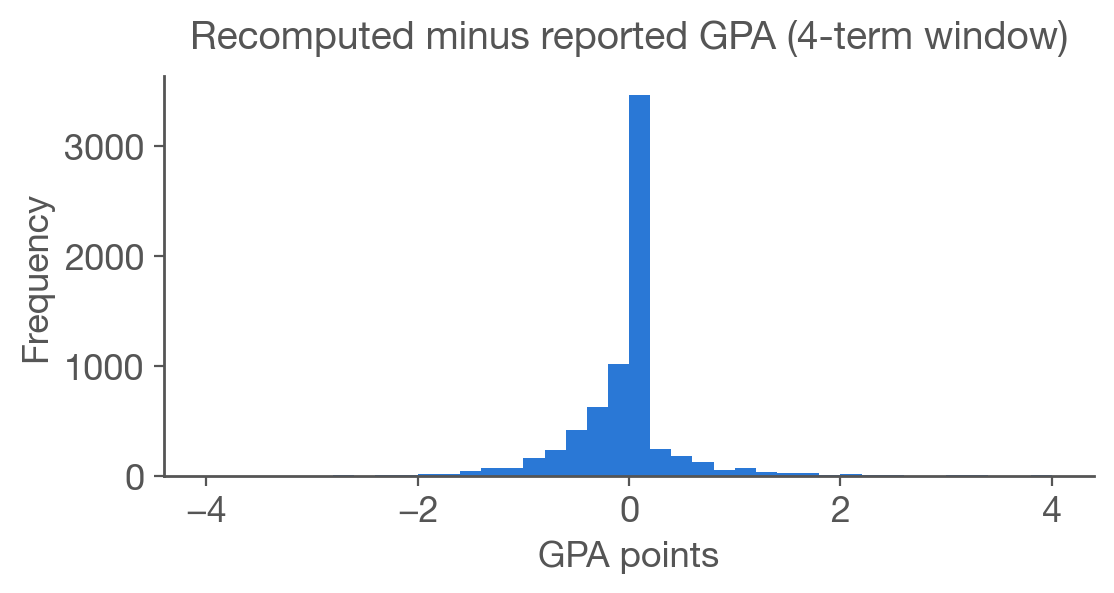

In [90]:
c = classes.drop_duplicates().merge(cohort[KEY + ["Cohort_Term"]], on=KEY, suffixes=("", "_cohort"))
c["term_n"] = year(c.Academic_Year) * 4 + c.Academic_Term.map(TERM_ORDER)
c["start_n"] = year(c.Cohort) * 4 + c.Cohort_Term_cohort.map(TERM_ORDER)
c["att"], c["grade"] = num(c.Number_of_Credits_Attempted), pd.to_numeric(c.Grade, errors="coerce")
by_label = year(c.Academic_Year) == year(c.Cohort)
rolling = (c.term_n >= c.start_n) & (c.term_n < c.start_n + 4)
c["in_y1"] = np.where(c.Cohort_Term_cohort == "FALL", by_label, rolling)

x = cohort.set_index(KEY)
reported_att = num(x.Number_of_Credits_Attempted_Yr_1)
course_att = c[c.in_y1].groupby(KEY).att.sum().reindex(x.index).fillna(0)
att_mismatch = reported_att.notna() & ((course_att - reported_att).abs() >= 0.01)
print(f"credits: {att_mismatch.sum():,} of {reported_att.notna().sum():,} differ ({att_mismatch.sum() / reported_att.notna().sum():.1%})")


def y1_gpa(window):
    g = c[window & c.grade.notna() & (c.att > 0)]
    s = g.assign(points=g.grade * g.att).groupby(KEY)[["points", "att"]].sum()
    return s.points / s.att


reported_gpa = pd.to_numeric(x.GPA_Group_Year_1, errors="coerce")
for name, window in [("academic-year label", by_label), ("4 terms from first term", rolling)]:
    diff = (y1_gpa(window).reindex(x.index) - reported_gpa).dropna()
    print(f"GPA ({name}): {(diff.abs() > 0.01).mean():.1%} of {len(diff):,} differ by more than 0.01")
diff.clip(-4, 4).plot.hist(bins=40, color="#2a78d6", figsize=(6, 2.5), title="Recomputed minus reported GPA (4-term window)")
plt.xlabel("GPA points")
plt.show()

> **Recommended:** Keep reported credits and GPA. Add recomputed course-based credits alongside them and flag disagreements; clarify PDP's definition of year 1 before replacing totals.


In [44]:
# Preserve reported values, add recomputed credits, and flag differences.
# Replacing totals requires confirmation of PDP's year-1 definition and source data.
fixed = x.copy()
fixed["yr1_credits_from_courses"] = course_att
fixed["yr1_credits_mismatch"] = att_mismatch
before_after("credit mismatches without a flag", att_mismatch.sum(), (att_mismatch & ~fixed.yr1_credits_mismatch).sum())

credit mismatches without a flag: 1,303 before -> 0 after


#### S6. Full-Time students with fewer than 12 first-term credits

The check uses 12 credits as the full-time threshold. Almost all flagged students started in Summer. A lower institutional threshold for Summer could explain their Full-Time status.

In [45]:
first_term = c[c.term_n == c.start_n].groupby(KEY).att.sum()
intensity = x.Enrollment_Intensity_First_Term
ft_low = (intensity == "Full-Time") & (first_term.reindex(x.index) < 12)
print(x.Cohort_Term[ft_low].value_counts().to_dict())
show("Full-Time with < 12 first-term course credits", ft_low.to_numpy(), x.assign(first_term_credits=first_term).reset_index(),
     ["Student_GUID", "Cohort_Term", "Enrollment_Intensity_First_Term", "first_term_credits"])

{'SUMMER': 179, 'FALL': 3}
Full-Time with < 12 first-term course credits: 182


,Student_GUID,Cohort_Term,Enrollment_Intensity_First_Term,first_term_credits
2,00A0A4D90DC29305E06349C8C70A4573,SUMMER,Full-Time,6.0
3,00DDDBC0048694ADE0634AC8C70A3682,SUMMER,Full-Time,6.0
52,025AAC5C188659E1E0634F0F210A8B25,SUMMER,Full-Time,6.0


> **Recommended:** Preserve Full-Time status and flag students below 12 first-term credits. Confirm the institution's threshold for each term, especially Summer.


In [46]:
# Preserve Full-Time status and flag records below 12 credits pending confirmation of the term's threshold.
fixed = x.copy()
fixed["full_time_under_12"] = ft_low
before_after("unflagged Full-Time under 12 credits", ft_low.sum(), (ft_low & ~fixed.full_time_under_12).sum())

unflagged Full-Time under 12 credits: 182 before -> 0 after


#### 11. Cohort_Term differences between files

Both files contain Cohort_Term. The flagged course rows differ from the cohort-file value, including differences across rows for the same student and cohort. Most of these course-file values match the row's Academic_Term.

In [47]:
j = course[KEY + ["Cohort_Term", "Academic_Term"]].merge(cohort[KEY + ["Cohort_Term"]], on=KEY, how="left", suffixes=("", "_cohort_file"))
term_diff = pd.Series((j.Cohort_Term != j.Cohort_Term_cohort_file).to_numpy(), index=course.index)
print(f"students: {course.loc[term_diff, 'Student_GUID'].nunique()}, rows copying Academic_Term: {(term_diff & (course.Cohort_Term == course.Academic_Term)).sum():,}")
show("rows that disagree", term_diff, j.set_index(course.index), ["Student_GUID", "Academic_Term", "Cohort_Term", "Cohort_Term_cohort_file"])

students: 886, rows copying Academic_Term: 3,720
rows that disagree: 4,307


,Student_GUID,Academic_Term,Cohort_Term,Cohort_Term_cohort_file
124,013F805FB5B842B1E0531B64C70A981A,SPRING,SPRING,FALL
128,013F805FB5B842B1E0531B64C70A981A,SPRING,SPRING,FALL
129,013F805FB5B842B1E0531B64C70A981A,SPRING,SPRING,FALL


> **Recommended:** Use the cohort file as the source of truth for Cohort_Term and copy it to course rows using Student_GUID and Cohort. The loader preserves the course-file value separately.


In [48]:
# Copy the cohort file's start term to matching course rows.
fixed = course.copy()
fixed["Cohort_Term"] = j.Cohort_Term_cohort_file.to_numpy()
before_after("rows that disagree", term_diff.sum(), (fixed.Cohort_Term != j.Cohort_Term_cohort_file.to_numpy()).sum())
# The loader retains course_enrollment.course_file_cohort_term and uses the cohort source for cohort_membership.cohort_term.

rows that disagree: 4,307 before -> 0 after


#### 14. Classes before the cohort year while Dual_and_Summer_Enrollment = UK

Course records precede the cohort year by up to nine years. Dual enrollment (DE) or summer enrollment before entry (SE, DS) may explain earlier classes. Most affected students have Dual_and_Summer_Enrollment = UK, which leaves that explanation unconfirmed.

In [49]:
early = course[has_class & (course_year < year(course.Cohort))].merge(cohort[KEY + ["Dual_and_Summer_Enrollment"]], on=KEY)
early["years_early"] = year(early.Cohort) - year(early.Academic_Year)
per_student = early.groupby(KEY).Dual_and_Summer_Enrollment.first()
print(f"early rows: {len(early)}, students: {len(per_student)}, of which UK: {(per_student == 'UK').sum()} ({(early.Dual_and_Summer_Enrollment == 'UK').sum()} rows)")
pd.crosstab(early.years_early, early.Dual_and_Summer_Enrollment)

early rows: 365, students: 112, of which UK: 86 (282 rows)


Dual_and_Summer_Enrollment,DE,DS,SE,UK
years_early,,,,
1,34,8,15,155
2,12,0,0,38
3,3,0,0,12
4,0,0,0,12
5,0,0,0,34
6,0,0,0,28
7,1,0,0,0
8,0,0,0,2
9,3,0,0,1


> **Recommended:** Flag pre-cohort class rows so first-year metrics can exclude them. Leave Dual_and_Summer_Enrollment unchanged because these classes may represent dual enrollment, summer work or errors.


In [50]:
# Flag pre-cohort classes for exclusion from first-year metrics.
# Preserve Dual_and_Summer_Enrollment pending confirmation of the earlier enrollment history.
fixed = course.copy()
fixed["pre_cohort"] = has_class & (course_year < year(course.Cohort))
before_after("pre-cohort class rows without a flag", len(early), len(early) - fixed.pre_cohort.sum())

pre-cohort class rows without a flag: 365 before -> 0 after


#### N15. Retention and year-2 enrollment differences

Retention = 1 indicates enrollment in year 2 or a credential by year 2. The checks identify students with Retention = 0 and year-2 classes, and students with Retention = 1 who lack both year-2 classes and a reported credential.

In [51]:
y2_rows = classes[year_n[has_class] == 2]
has_y2 = pd.Series(in_rows(y2_rows), index=cohort.index)
cred_by_y2 = num(cohort.First_Year_to_A_or_C_at_cohort).between(1, 2) | num(cohort.First_Year_to_Bachelors_at_coh).between(1, 2)
ret0_y2 = (cohort.Retention == "0") & has_y2
ret1_none = (cohort.Retention == "1") & ~has_y2 & ~cred_by_y2
print("Retention = 0 but has year-2 classes:", ret0_y2.sum())
print("Retention = 1 with no year-2 classes and no credential:", ret1_none.sum())

Retention = 0 but has year-2 classes: 490
Retention = 1 with no year-2 classes and no credential: 624


 490
Retention = 1 with no year-2 classes and no credential: 624


> **Recommended:** Preserve Retention and flag both differences. PDP may calculate retention from records absent from the course file.


In [52]:
# Preserve Retention, which may depend on other source data, and flag both differences.
fixed = cohort.copy()
fixed["retention_conflict"] = ret0_y2 | ret1_none
before_after("unflagged retention conflicts", (ret0_y2 | ret1_none).sum(), ((ret0_y2 | ret1_none) & ~fixed.retention_conflict).sum())

unflagged retention conflicts: 1,114 before -> 0 after


#### N17. Students with no class rows

Students without class records include those absent from the course file, those with the empty rows in issue 12, and those with only term records at other colleges. The cohort file reports first-year credits for many of these students.

In [53]:
no_class = ~pd.Series(in_rows(classes), index=cohort.index)
print(f"with Yr1 credits attempted > 0: {(no_class & (num(cohort.Number_of_Credits_Attempted_Yr_1) > 0)).sum()}")
show("students with no class rows", no_class, cohort, KEY + ["Number_of_Credits_Attempted_Yr_1"])

with Yr1 credits attempted > 0: 385
students with no class rows: 578


,Student_GUID,Cohort,Number_of_Credits_Attempted_Yr_1
1,006F3FF4E1F908EFE0535964C70A009A,2024-25,12
17,014231714EB21F9FE063630F210A0A94,2023-24,26
56,029358E6EA6F66F5E0531B64C70A9A58,2023-24,13


> **Recommended:** Flag students with no class rows and exclude them from course-based metrics. Treat their course histories as unavailable.


In [54]:
# Flag unavailable course histories for exclusion from course-based metrics.
fixed = cohort.copy()
fixed["no_class_rows"] = no_class
before_after("students with no class rows and no flag", no_class.sum(), (no_class & ~fixed.no_class_rows).sum())

students with no class rows and no flag: 578 before -> 0 after


#### N18. First class before Cohort_Term within the cohort year

The flagged students have a first class at the cohort institution in a term before Cohort_Term within the same academic year.

In [55]:
own = classes[classes.Enrolled_at_Other_Institution_s_.isin(["N", "Y"])]
first = (year(own.Academic_Year) * 10 + own.Academic_Term.map(TERM_ORDER)).groupby([own.Student_GUID, own.Cohort]).min().rename("first_n")
f = cohort.merge(first, left_on=KEY, right_index=True)
start = year(f.Cohort) * 10 + f.Cohort_Term.map(TERM_ORDER)
too_early = (f.first_n < start) & (f.first_n // 10 == year(f.Cohort))
show("first class in an earlier term of the cohort year", too_early, f, KEY + ["Cohort_Term", "first_n"])

first class in an earlier term of the cohort year: 61


,Student_GUID,Cohort,Cohort_Term,first_n
59,02A800F546C02D29E0535964C70AD592,2022-23,SPRING,20220
200,0429E30590B1425DE0634F0F210A48B1,2024-25,SUMMER,20240
509,05A94D414FD80D83E0634F0F210A158D,2023-24,SUMMER,20230


> **Recommended:** Preserve both terms and flag first classes before Cohort_Term for provider review. The files alone cannot identify the incorrect term.


In [56]:
# Preserve both terms and flag their difference for provider review.
fixed = f.copy()
fixed["first_class_before_cohort_term"] = too_early
before_after("unflagged", too_early.sum(), (too_early & ~fixed.first_class_before_cohort_term).sum())

unflagged: 61 before -> 0 after


## Gateway and developmental flags

#### N1. Required students with an unknown gateway attempt are coded D

Most required students with AttemptedGateway…Year1 = UK have CompletedGateway…Year1 = D. The dictionary defines D as "did not complete", so this combination may be valid. The missing attempt information limits interpretation, and including these records as failures can lower completion rates.

In [57]:
for subj in ("Math", "English"):
    required = cohort[f"Gateway_{subj}_Status"] == "R"
    print(f"{subj}, Gateway_{subj}_Status = R: attempt (rows) by completion (columns)")
    display(pd.crosstab(cohort.loc[required, f"AttemptedGateway{subj}Year1"].replace("", "(blank)"),
                        cohort.loc[required, f"CompletedGateway{subj}Year1"].replace("", "(blank)")))

Math, Gateway_Math_Status = R: attempt (rows) by completion (columns)


CompletedGatewayMathYear1,(blank),C,D
AttemptedGatewayMathYear1,,,
(blank),36,0,0
N,0,1,941
UK,7,2,1821
Y,2,1216,426


English, Gateway_English_Status = R: attempt (rows) by completion (columns)


CompletedGatewayEnglishYear1,(blank),C,D
AttemptedGatewayEnglishYear1,,,
(blank),60,0,0
N,0,0,446
UK,12,1,1854
Y,5,2005,602


> **Recommended:** Preserve D and flag students with unknown attempts. Compare completion rates with and without these records, and confirm PDP's treatment of unknown attempts.


In [58]:
# Preserve D and flag unknown attempts for completion-rate comparisons and provider review.
fixed = cohort.copy()
for subj in ("Math", "English"):
    fixed[f"gateway_{subj.lower()}_d_unknown_attempt"] = (cohort[f"AttemptedGateway{subj}Year1"] == "UK") & (cohort[f"CompletedGateway{subj}Year1"] == "D")
print("flagged:", fixed.filter(like="_d_unknown_attempt").sum().to_dict())

flagged: {'gateway_math_d_unknown_attempt': 1821, 'gateway_english_d_unknown_attempt': 1854}


#### N2. Gateway flag inconsistencies within the cohort file

Gateway completion requires an attempt and a grade of at least 1 or P. Required students also need a recorded attempt status. A completed course with an unknown attempt warrants review because the attempt may be unrecorded.

In [59]:
def gateway_conflicts(df, subj):
    att, done = df[f"AttemptedGateway{subj}Year1"], df[f"CompletedGateway{subj}Year1"]
    grade = df[f"Gateway{subj}GradeY1"]
    return pd.DataFrame({
        "not attempted but completed": (att == "N") & (done == "C"),
        "unknown attempt but completed (suspect)": (att == "UK") & (done == "C"),
        "completed with grade < 1 or F/W/I": (done == "C") & ((pd.to_numeric(grade, errors="coerce") < 1) | grade.isin(["F", "W", "I"])),
        "required with blank attempt": (df[f"Gateway_{subj}_Status"] == "R") & (att == ""),
    })

pd.DataFrame({s: gateway_conflicts(cohort, s).sum() for s in ("Math", "English")})

,Math,English
not attempted but completed,1,0
unknown attempt but completed (suspect),2,1
completed with grade < 1 or F/W/I,3,10
required with blank attempt,36,60


> **Recommended:** Preserve the original gateway flags and record inconsistencies separately for Math and English. Confirm corrections with the provider.


In [60]:
# Preserve source values and flag gateway inconsistencies by subject.
fixed = cohort.copy()
for subj in ("Math", "English"):
    fixed[f"gateway_{subj.lower()}_conflict"] = gateway_conflicts(cohort, subj).any(axis=1)
total = sum(gateway_conflicts(cohort, s).any(axis=1).sum() for s in ("Math", "English"))
before_after("unflagged conflicts", total, sum((gateway_conflicts(cohort, s).any(axis=1) & ~fixed[f"gateway_{s.lower()}_conflict"]).sum() for s in ("Math", "English")))

unflagged conflicts: 113 before -> 0 after


#### N3. Gateway flag and course-record differences

The checks compare cohort gateway flags with year-1 course rows where Math_or_English_Gateway = M or E. An attempt or completion flag without a matching course row requires review. Students with no gateway requirement at entry can still take and pass the course; the table includes those cases for context.

In [61]:
gw_y1 = classes[classes.Math_or_English_Gateway.isin(["M", "E"]) & (year_n[has_class] == 1)]
gw_grade = pd.to_numeric(gw_y1.Grade, errors="coerce")
gw_pass = gw_y1[(gw_grade >= 1) | (gw_y1.Grade == "P")]


def flag_vs_rows(subj, code):
    took = in_rows(gw_y1[gw_y1.Math_or_English_Gateway == code])
    passed = in_rows(gw_pass[gw_pass.Math_or_English_Gateway == code])
    return pd.DataFrame({
        "attempted Y, no year-1 gateway row": (cohort[f"AttemptedGateway{subj}Year1"] == "Y") & ~took,
        "completed C, no year-1 gateway row": (cohort[f"CompletedGateway{subj}Year1"] == "C") & ~took,
        "not required (N) but passed one (info, not a conflict)": (cohort[f"Gateway_{subj}_Status"] == "N") & passed,
    })

gw_checks = {"Math": flag_vs_rows("Math", "M"), "English": flag_vs_rows("English", "E")}
pd.DataFrame({s: t.sum() for s, t in gw_checks.items()})

,Math,English
"attempted Y, no year-1 gateway row",203,195
"completed C, no year-1 gateway row",152,149
"not required (N) but passed one (info, not a conflict)",326,238


> **Recommended:** Flag gateway attempts or completions without matching course records; either source may be incomplete. Keep successful completions by students with no gateway requirement as informational cases.


In [62]:
# Flag missing course evidence for reported attempts or completions; exclude informational cases.
fixed = cohort.copy()
conflicts = {s: t.iloc[:, :2].any(axis=1) for s, t in gw_checks.items()}
for subj, c in conflicts.items():
    fixed[f"gateway_{subj.lower()}_vs_courses"] = c
before_after("unflagged students", sum(c.sum() for c in conflicts.values()),
             sum((c & ~fixed[f"gateway_{s.lower()}_vs_courses"]).sum() for s, c in conflicts.items()))

unflagged students: 402 before -> 0 after


#### N4. Gateway flag on developmental courses

Gateway courses are college-level. Records with Math_or_English_Gateway = M or E and developmental Course_Type CC or CD can add developmental classes to gateway-attempt counts.

In [60]:
dev_gw = classes.Math_or_English_Gateway.isin(["M", "E"]) & classes.Course_Type.isin(["CC", "CD"])
print(pd.crosstab(classes.Course_Type[dev_gw], classes.Math_or_English_Gateway[dev_gw]).to_dict("index"))
show("gateway-flagged developmental rows", dev_gw, classes, ["Course_Prefix", "Course_Number", "Course_Name", "Course_Type", "Math_or_English_Gateway"])

{'CC': {'E': 417, 'M': 360}, 'CD': {'E': 90, 'M': 112}}
gateway-flagged developmental rows: 979


,Course_Prefix,Course_Number,Course_Name,Course_Type,Math_or_English_Gateway
125,MATH,116,MATH-116,CC,M
326,ENG,101,ENG-101,CC,E
431,MATH,104B,MATH-104B,CC,M


> **Recommended:** Preserve and flag gateway indicators on developmental courses so analyses can exclude them. Confirm whether these records represent co-requisite pairings.


In [61]:
# Preserve potential co-requisite pairings and flag them for exclusion from gateway counts.
fixed = classes.copy()
fixed["gateway_on_dev_course"] = dev_gw
before_after("gateway rows on dev courses, unflagged", dev_gw.sum(), (dev_gw & ~fixed.gateway_on_dev_course).sum())

gateway rows on dev courses, unflagged: 979 before -> 0 after


#### N5. Developmental completion uses Y/N instead of C/D

The dictionary lists C, D and NA for CompletedDev…Y1. The file contains Y, N and NA, including completion codes for students with no reported developmental attempt.

In [62]:
for subj in ("Math", "English"):
    att, done = cohort[f"AttemptedDev{subj}Y1"], cohort[f"CompletedDev{subj}Y1"]
    print(f"{subj}: not attempted but has Y/N: {((att == 'N') & done.isin(['Y', 'N'])).sum()}")
    display(pd.crosstab(att.replace("", "(blank)"), done.replace("", "(blank)")))

Math: not attempted but has Y/N: 432


CompletedDevMathY1,(blank),N,NA,Y
AttemptedDevMathY1,,,,
(blank),198,0,0,0
N,0,426,809,6
NA,0,0,3978,0
UK,0,0,4051,0
Y,0,418,308,119


English: not attempted but has Y/N: 255


CompletedDevEnglishY1,(blank),N,NA,Y
AttemptedDevEnglishY1,,,,
(blank),198,0,0,0
N,0,238,514,17
NA,0,0,4684,0
UK,0,0,4102,0
Y,0,305,127,128


> **Recommended:** Confirm that Y means completed before using the Y/N to C/D mapping. Flag completion with no reported attempt. Preserve D for students with no attempt because that combination can be valid.


In [63]:
# Map Y/N to C/D under the assumption that Y means completed; confirm with Achieving the Dream.
# Flag completion with no attempt and preserve the potentially valid no-attempt + D combination.
def dev_problems(df):
    return sum((df[f"CompletedDev{s}Y1"].isin(["Y", "N"])).sum() for s in ("Math", "English"))

fixed = cohort.copy()
for subj in ("Math", "English"):
    done = f"CompletedDev{subj}Y1"
    fixed[done] = fixed[done].replace({"Y": "C", "N": "D"})
    fixed[f"dev_{subj.lower()}_completed_not_attempted"] = (fixed[f"AttemptedDev{subj}Y1"] == "N") & (fixed[done] == "C")
before_after("completion values not in the dictionary (Y/N)", dev_problems(cohort), dev_problems(fixed))
print("flagged completed but not attempted:", fixed.filter(like="completed_not_attempted").sum().to_dict())
# Loader rules: data_fixes.yaml `dev_math_completion_is_c_d` and `dev_english_completion_is_c_d`.

completion values not in the dictionary (Y/N): 1,657 before -> 0 after
flagged completed but not attempted: {'dev_math_completed_not_attempted': 6, 'dev_english_completed_not_attempted': 17}


## Codes, formats and nulls

#### 7 (7a–7c). Codes not in the dictionary: Pell_Status_First_Year, Math_or_English_Gateway, Credential_Type_Sought_Year_1

Pell_Status_First_Year contains the undocumented code U. Math_or_English_Gateway contains NA in place of the documented N; N never occurs. Credential_Type_Sought_Year_1 contains text labels where the dictionary specifies codes, including both "Teach" and "Teacher" in the teacher-certification label.

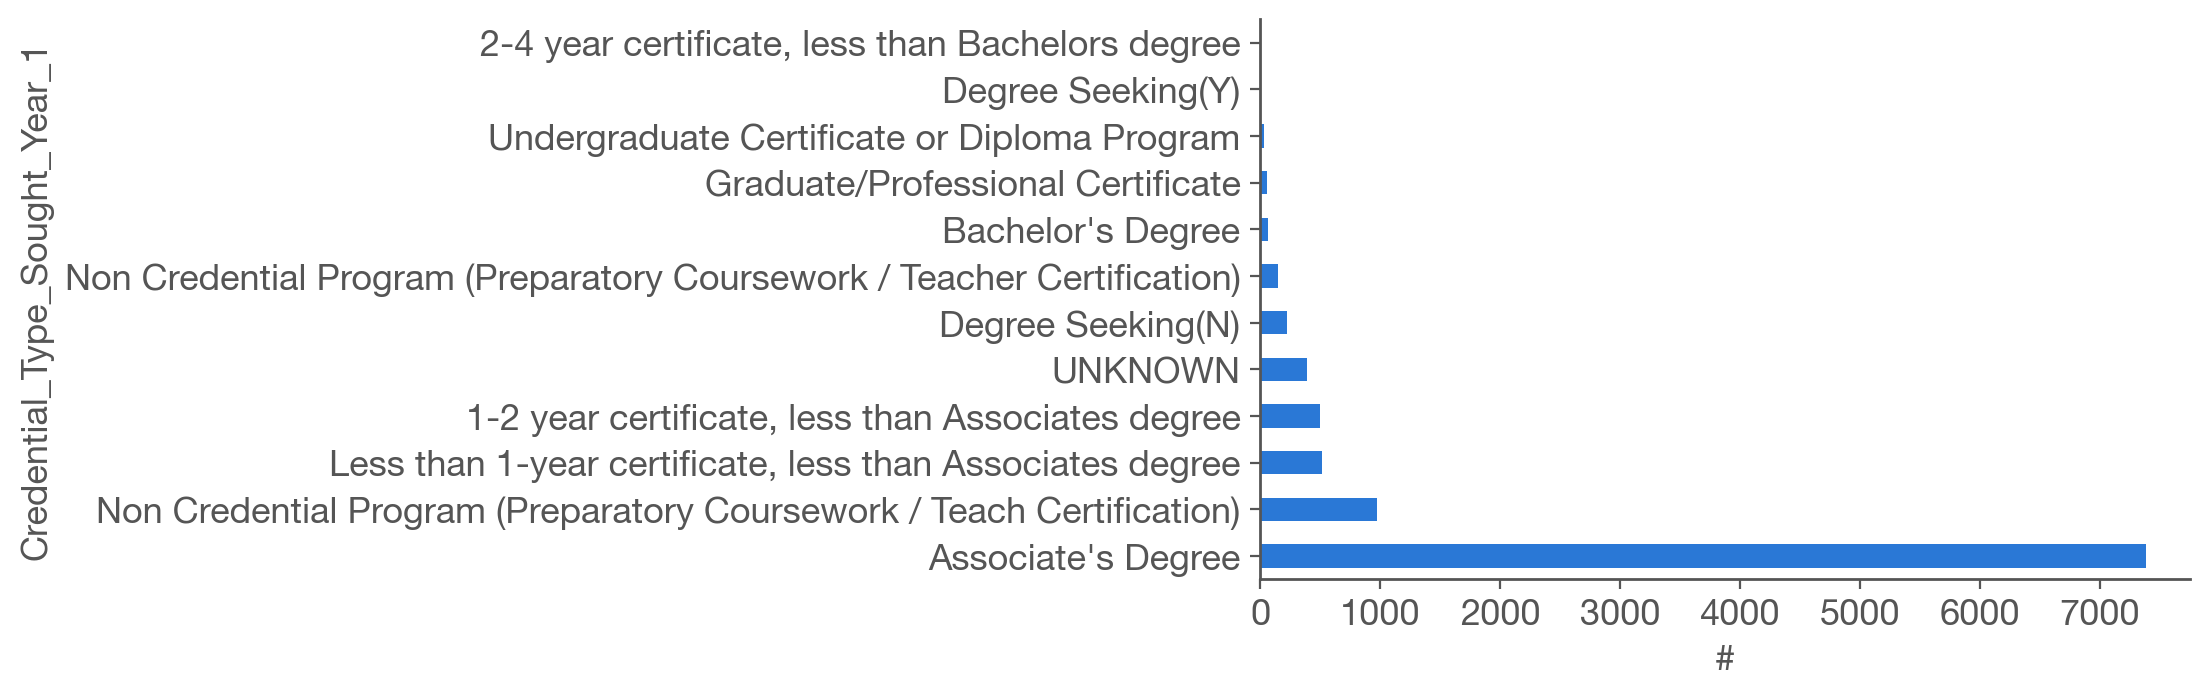

In [80]:
ax = cohort.Credential_Type_Sought_Year_1.value_counts().plot.barh(color="#2a78d6", figsize=(6, 3.5))
ax.set_xlabel('#');

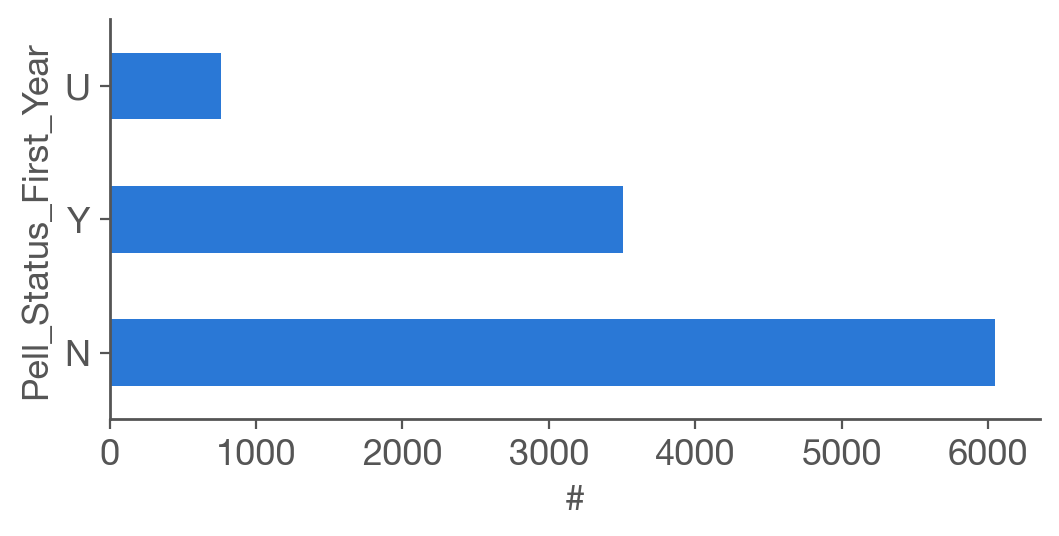

In [81]:
ax = cohort.Pell_Status_First_Year.value_counts(dropna=False).plot.barh(color="#2a78d6", figsize=(6, 2.5));
ax.set_xlabel("#");

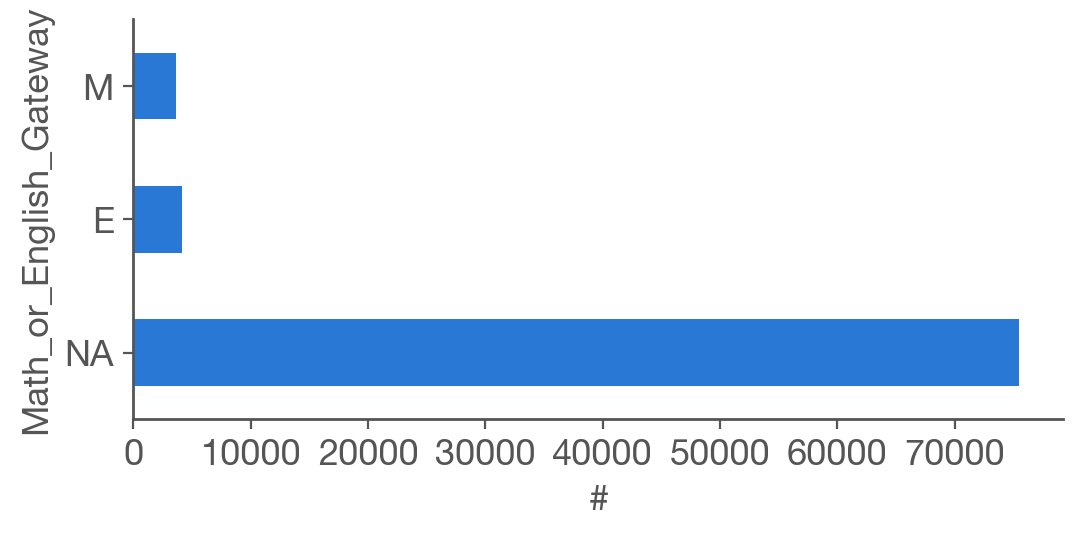

In [82]:
ax = classes.Math_or_English_Gateway.value_counts(dropna=False).plot.barh(color="#2a78d6", figsize=(6, 2.5));
ax.set_xlabel("#");

In [67]:
print("Pell_Status_First_Year = U:", (cohort.Pell_Status_First_Year == "U").sum())
print("Math_or_English_Gateway on class rows:", classes.Math_or_English_Gateway.value_counts().to_dict())

Pell_Status_First_Year = U: 759
Math_or_English_Gateway on class rows: {'NA': 75504, 'E': 4105, 'M': 3587}


> **Recommended:** Normalize Pell U to UK, gateway NA to N on class rows, and recognized credential labels to the loader's codes. Leave Degree Seeking(N)/(Y) and UNKNOWN unchanged because they have no mapped credential code.


In [66]:
# Use the loader's credential map; preserve unmapped Degree Seeking(N)/(Y) and UNKNOWN values.
CREDENTIAL_CODES = {
    "Associate's Degree": "A",
    "Non Credential Program (Preparatory Coursework / Teach Certification)": "NC",
    "Non Credential Program (Preparatory Coursework / Teacher Certification)": "NC",
    "Less than 1-year certificate, less than Associates degree": "C1",
    "1-2 year certificate, less than Associates degree": "C2",
    "2-4 year certificate, less than Bachelors degree": "C4",
    "Bachelor's Degree": "B",
    "Graduate/Professional Certificate": "PC",
    "Undergraduate Certificate or Diploma Program": "01",
}


def code_problems(co_df, cr_df):
    return pd.Series({
        "Pell U": (co_df.Pell_Status_First_Year == "U").sum(),
        "gateway NA": (cr_df.Math_or_English_Gateway[cr_df.Course_Prefix != ""] == "NA").sum(),
        "credential labels": co_df.Credential_Type_Sought_Year_1.isin(CREDENTIAL_CODES).sum(),
    })

fixed_co, fixed_cr = cohort.copy(), course.copy()
fixed_co["Pell_Status_First_Year"] = fixed_co.Pell_Status_First_Year.replace("U", "UK")  # unknown; no code in the dictionary
fixed_cr.loc[has_class, "Math_or_English_Gateway"] = fixed_cr.Math_or_English_Gateway.replace("NA", "N")
fixed_co["Credential_Type_Sought_Year_1"] = fixed_co.Credential_Type_Sought_Year_1.replace(CREDENTIAL_CODES)
pd.DataFrame({"before": code_problems(cohort, course), "after": code_problems(fixed_co, fixed_cr)})
# Loader rules: data_fixes.yaml `gateway_na_is_n` and `credential_labels_are_codes`; the loader preserves Pell U.

,before,after
Pell U,759,0
gateway NA,75504,0
credential labels,9678,0


#### N6. Additional undocumented values

Additional undocumented values include unknown markers (Unknown, UK, -1, NA and MIS), attendance statuses (Continuing and Re-admit), and grade codes (OTH, UW, N and CHE). Their interpretation depends on the column.

Student_Age = Unknown                            1
Enrollment_Type = Continuing                     2
Enrollment_Intensity_First_Term = Unknown      267
Attendance_Status_Term_1 not listed            620
GPA_Group_Term_1 = UK                          603
GPA_Group_Year_1 = UK                          576
Grade OTH/UW/N/MIS/CHE/UK                       96
Course_Instructor_Rank = -1                  77800
Section_ID = NA                                205
Section_ID = UK                                 50
dtype: int64

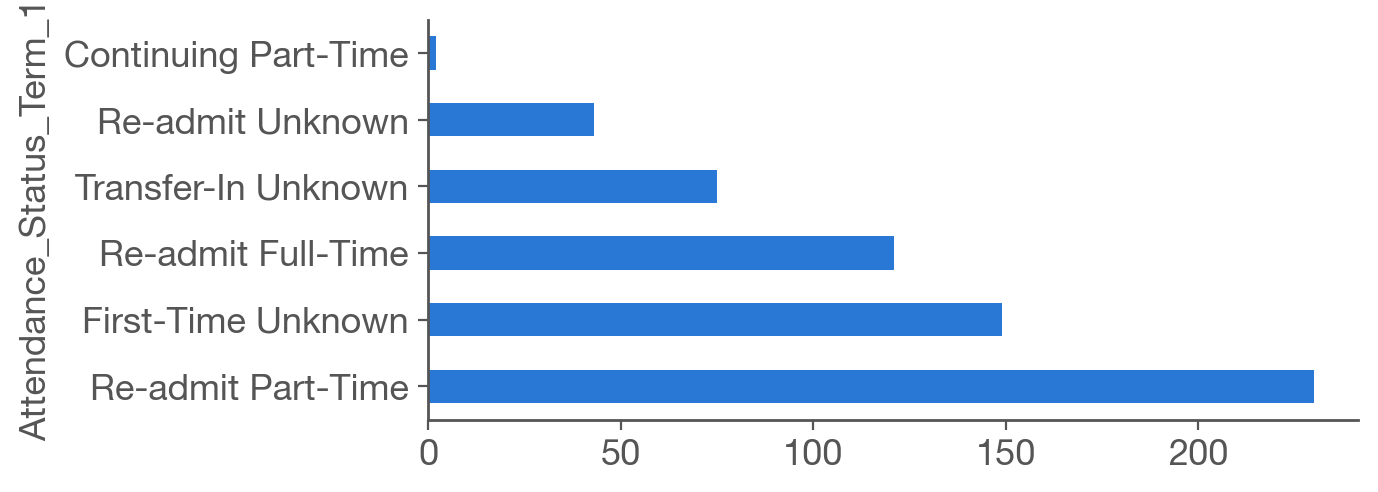

In [86]:
ATTENDANCE = ["First-Time Full-Time", "First-Time Part-Time", "Transfer-In Full-Time", "Transfer-In Part-Time"]
undictionaried = pd.Series({
    "Student_Age = Unknown": (cohort.Student_Age == "Unknown").sum(),
    "Enrollment_Type = Continuing": (cohort.Enrollment_Type == "Continuing").sum(),
    "Enrollment_Intensity_First_Term = Unknown": (cohort.Enrollment_Intensity_First_Term == "Unknown").sum(),
    "Attendance_Status_Term_1 not listed": (~cohort.Attendance_Status_Term_1.isin(ATTENDANCE)).sum(),
    "GPA_Group_Term_1 = UK": (cohort.GPA_Group_Term_1 == "UK").sum(),
    "GPA_Group_Year_1 = UK": (cohort.GPA_Group_Year_1 == "UK").sum(),
    "Grade OTH/UW/N/MIS/CHE/UK": classes.Grade.isin(["OTH", "UW", "N", "MIS", "CHE", "UK"]).sum(),
    "Course_Instructor_Rank = -1": (course.Course_Instructor_Rank == "-1").sum(),
    "Section_ID = NA": (course.Section_ID == "NA").sum(),
    "Section_ID = UK": (course.Section_ID == "UK").sum(),
})
cohort.Attendance_Status_Term_1[~cohort.Attendance_Status_Term_1.isin(ATTENDANCE)].value_counts().plot.barh(color="#2a78d6", figsize=(6, 2.5))
print("\n")
undictionaried

> **Recommended:** Convert unknown markers to missing values with column-specific mappings. Preserve undocumented codes such as Continuing, Re-admit, OTH, UW, N and CHE until Achieving the Dream confirms their definitions.


In [87]:
# Convert unknown markers to NaN by column.
# Preserve undocumented status and grade codes pending confirmation from Achieving the Dream.
UNKNOWN_CODES = {
    "Student_Age": ["Unknown"], "Enrollment_Intensity_First_Term": ["Unknown"],
    "GPA_Group_Term_1": ["UK"], "GPA_Group_Year_1": ["UK"],
    "Grade": ["UK", "MIS"], "Course_Instructor_Rank": ["-1"], "Section_ID": ["NA", "UK"],
}
fixed_co, fixed_cr = cohort.copy(), course.copy()
for df in (fixed_co, fixed_cr):
    for col in UNKNOWN_CODES.keys() & set(df.columns):
        df[col] = df[col].mask(df[col].isin(UNKNOWN_CODES[col]))
count = lambda co_df, cr_df: sum(d[col].isin(UNKNOWN_CODES[col]).sum() for d in (co_df, cr_df) for col in UNKNOWN_CODES.keys() & set(d.columns))
before_after("unknown-style markers", count(cohort, course), count(fixed_co, fixed_cr))
# course_mapping.yaml maps Section_ID [UK, Missing] and Grade [M, UK] to unknown.
# That mapping excludes Section_ID = NA and instructor rank -1.

unknown-style markers: 79,507 before -> 0 after


#### 13 (13a–13e) + N11 + N12 + N22. Truncated labels and numeric formatting

Race labels stop at 25 characters and C_Enrollment_Record_at_other at 50. Truncation can remove entries from the latter and break alignment with S_/L_ lists (N11). CIP and program-of-study codes lack leading zeros, Course_CIP includes two-digit integers that may be a series or a code that lost its decimals (N12) and codes that lost trailing zeros (N22), and Section_ID includes scientific notation.

In [88]:
TRUNCATED_RACE = ["American Indian or Alaska", "Native Hawaiian or Other"]
parts = lambda s: s.str.count(r"\|")


def format_problems(co_df, cr_df):
    cip = cr_df.Course_CIP[cr_df.Course_Prefix != ""]
    other = cr_df[cr_df.S_Enrollment_Record_at_other != ""]
    return pd.Series({
        "Race truncated (cohort)": co_df.Race.isin(TRUNCATED_RACE).sum(),
        "Race truncated (course)": cr_df.Race.isin(TRUNCATED_RACE).sum(),
        "Course_CIP leading zero lost": cip.str.fullmatch(r"\d(\.\d+)?").sum(),
        "N12. Course_CIP is a two-digit integer": cip.str.fullmatch(r"\d{2}").sum(),
        "N22. Course_CIP trailing zeros lost": cip.str.fullmatch(r"\d{1,2}\.\d{3}|\d{2}\.\d").sum(),
        "Program_of_Study_Term_1 5 digits": (co_df.Program_of_Study_Term_1.str.len() == 5).sum(),
        "Program_of_Study_Year_1 5 digits": (co_df.Program_of_Study_Year_1.str.len() == 5).sum(),
        "Term_Program_of_Study 5 digits": (cr_df.Term_Program_of_Study.str.len() == 5).sum(),
        "Section_ID in scientific notation": cr_df.Section_ID.str.contains(r"E\+").sum(),
        "C_Enrollment_Record_at_other cut at 50": (cr_df.C_Enrollment_Record_at_other.str.len() == 50).sum(),
        "N11. C_ no longer lines up with S_": (parts(other.S_Enrollment_Record_at_other) != parts(other.C_Enrollment_Record_at_other)).sum(),
    })

format_problems(cohort, course)

Race truncated (cohort)                    225
Race truncated (course)                   1798
Course_CIP leading zero lost              1638
N12. Course_CIP is a two-digit integer     471
N22. Course_CIP trailing zeros lost        704
Program_of_Study_Term_1 5 digits            96
Program_of_Study_Year_1 5 digits           113
Term_Program_of_Study 5 digits             605
Section_ID in scientific notation           68
C_Enrollment_Record_at_other cut at 50     109
N11. C_ no longer lines up with S_           9
dtype: int64

> **Recommended:** Restore recoverable race labels and leading zeros in CIP families and six-digit program codes, and the trailing zeros CIP codes lost. Flag integer CIPs, scientific-notation Section_ID values and truncated institution-type text. Recovering lost detail requires the original records.


In [89]:
# Restore full Race labels, leading zeros in CIP families and six-digit program codes, and CIP trailing zeros.
# Flag integer CIPs, scientific-notation Section_ID values and truncated institution-type text.
fixed_co, fixed_cr = cohort.copy(), course.copy()
RACE = dict(zip(TRUNCATED_RACE, ["American Indian or Alaska Native", "Native Hawaiian or Other Pacific Islander"]))
for df in (fixed_co, fixed_cr):
    df["Race"] = df.Race.replace(RACE)
cip = fixed_cr.Course_CIP.str.extract(r"^(\d{1,2})(\.\d+)?$")
fixed_cr.loc[cip[0].notna(), "Course_CIP"] = cip[0].str.zfill(2) + cip[1].fillna("")
trailing = fixed_cr.Course_CIP.str.fullmatch(r"\d{2}\.\d{3}|\d{2}\.\d")  # 13.121 is 13.1210; 45.1 is 45.10
fixed_cr.loc[trailing, "Course_CIP"] += "0"
for df, col in [(fixed_co, "Program_of_Study_Term_1"), (fixed_co, "Program_of_Study_Year_1"), (fixed_cr, "Term_Program_of_Study")]:
    df[col] = df[col].mask(df[col].str.len() == 5, df[col].str.zfill(6))
fixed_cr["format_lost"] = (fixed_cr.Course_CIP.str.fullmatch(r"\d+") | fixed_cr.Section_ID.str.contains(r"E\+")
                           | (fixed_cr.C_Enrollment_Record_at_other.str.len() == 50))
display(pd.DataFrame({"before": format_problems(cohort, course), "after": format_problems(fixed_co, fixed_cr)}))
print("course rows flagged format_lost:", fixed_cr.format_lost.sum())
# Loader rule: data_fixes.yaml `race_cut_at_25_characters` restores two Race labels; other values remain unchanged.

,before,after
Race truncated (cohort),225,0
Race truncated (course),1798,0
Course_CIP leading zero lost,1638,0
N12. Course_CIP is a two-digit integer,471,540
N22. Course_CIP trailing zeros lost,704,0
Program_of_Study_Term_1 5 digits,96,0
Program_of_Study_Year_1 5 digits,113,0
Term_Program_of_Study 5 digits,605,0
Section_ID in scientific notation,68,68
C_Enrollment_Record_at_other cut at 50,109,109


course rows flagged format_lost: 717


The examples below compare source values with the copies after the fix. Full race labels and leading zeros can be restored. Truncated institution text and rounded section identifiers require the original records. Two-digit CIP values may be a valid series or a shortened longer code. The fix preserves these values and flags the course rows for review.

The second table includes state and locale alongside truncated institution types so you can compare the list entries. All examples come from synthetic mock data.

In [4]:
examples = []
for source, original, corrected, column, mask, action in [
    ("cohort", cohort, fixed_co, "Race", cohort.Race.isin(TRUNCATED_RACE), "Restore full label"),
    ("course", course, fixed_cr, "Course_CIP", has_class & course.Course_CIP.str.fullmatch(r"\d\.\d+"), "Restore leading zero"),
    ("cohort", cohort, fixed_co, "Program_of_Study_Term_1", cohort.Program_of_Study_Term_1.str.len() == 5, "Restore leading zero"),
    ("cohort", cohort, fixed_co, "Program_of_Study_Year_1", cohort.Program_of_Study_Year_1.str.len() == 5, "Restore leading zero"),
    ("course", course, fixed_cr, "Term_Program_of_Study", course.Term_Program_of_Study.str.len() == 5, "Restore leading zero"),
    ("course", course, fixed_cr, "Course_CIP", has_class & course.Course_CIP.str.fullmatch(r"\d{1,2}\.\d{3}|\d{2}\.\d"), "Restore trailing zero"),
    ("course", course, fixed_cr, "Course_CIP", has_class & course.Course_CIP.str.fullmatch(r"\d{2}"), "Keep as written; flag missing detail"),
    ("course", course, fixed_cr, "Section_ID", course.Section_ID.str.contains(r"E\+"), "Preserve value; flag for review"),
    ("course", course, fixed_cr, "C_Enrollment_Record_at_other", course.C_Enrollment_Record_at_other.str.len() == 50, "Preserve value; flag for review"),
]:
    for idx in original.loc[mask].drop_duplicates(column).head(2).index:
        examples.append({
            "Source": source, "CSV row": int(idx) + 2, "Column": column,
            "Before": original.at[idx, column], "After": corrected.at[idx, column],
            "Action": action,
        })
format_examples = pd.DataFrame(examples)
truncated_indices = course.index[course.C_Enrollment_Record_at_other.str.len() == 50][:3]
truncated_examples = course.loc[truncated_indices, [
    "S_Enrollment_Record_at_other", "C_Enrollment_Record_at_other", "L_Enrollment_Record_at_other",
]].copy()
truncated_examples.insert(0, "CSV row", truncated_indices + 2)
truncated_examples["After: institution type"] = fixed_cr.loc[truncated_indices, "C_Enrollment_Record_at_other"]
truncated_examples["Flagged for review"] = fixed_cr.loc[truncated_indices, "format_lost"]
# Show full text so pandas' display limit does not hide the source truncation.
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(format_examples)
    display(truncated_examples.reset_index(drop=True))

,Source,CSV row,Column,Before,After,Action
0,cohort,54,Race,American Indian or Alaska,American Indian or Alaska Native,Restore full label
1,cohort,661,Race,Native Hawaiian or Other,Native Hawaiian or Other Pacific Islander,Restore full label
2,course,161,Course_CIP,5.0202,05.0202,Restore leading zero
3,course,257,Course_CIP,9.01,09.01,Restore leading zero
4,cohort,143,Program_of_Study_Term_1,90702,090702,Restore leading zero
5,cohort,244,Program_of_Study_Term_1,10307,010307,Restore leading zero
6,cohort,18,Program_of_Study_Year_1,18301,018301,Restore leading zero
7,cohort,45,Program_of_Study_Year_1,90101,090101,Restore leading zero
8,course,126,Term_Program_of_Study,18301,018301,Restore leading zero
9,course,329,Term_Program_of_Study,90101,090101,Restore leading zero


,CSV row,S_Enrollment_Record_at_other,C_Enrollment_Record_at_other,L_Enrollment_Record_at_other,After: institution type,Flagged for review
0,8,TX|KS,Master's Colleges & Universities|Doctoral Universi,Urban|Urban,Master's Colleges & Universities|Doctoral Universi,True
1,10,TX|KS,Master's Colleges & Universities|Doctoral Universi,Urban|Urban,Master's Colleges & Universities|Doctoral Universi,True
2,1275,CA|AZ|CA,Associate's Colleges|Doctoral Universities|Associa,Suburb|Urban|Suburb,Associate's Colleges|Doctoral Universities|Associa,True


#### N7. Mixed null markers

Missing and unknown values use several markers: blanks, ".", "NA", "UK", "Unknown", "UNKNOWN", "MISSING" and "-1". Meanings vary by column. For example, NA means not applicable in AttemptedGateway… and identifies Nursing Assistant courses in Course_Prefix. A global `na_values` list can erase valid codes.

In [70]:
MARKERS = ["", ".", "NA", "UK", "Unknown", "UNKNOWN", "MISSING", "-1"]
usage = pd.DataFrame({
    name: {m or "(blank)": f"{int((df == m).any().sum())} cols / {int((df == m).sum().sum()):,} cells" for m in MARKERS}
    for name, df in [("cohort", cohort), ("course", course)]
})
print("Course_CIP = MISSING:", (course.Course_CIP == "MISSING").sum())
print("AttemptedGatewayMathYear1:", cohort.AttemptedGatewayMathYear1.replace("", "(blank)").value_counts().to_dict())
usage

Course_CIP = MISSING: 16486
AttemptedGatewayMathYear1: {'UK': 4102, 'NA': 3427, 'Y': 1644, 'N': 942, '(blank)': 198}


,cohort,course
(blank),"35 cols / 225,286 cells","23 cols / 1,053,970 cells"
.,"9 cols / 10,104 cells","4 cols / 71,020 cells"
NA,"8 cols / 35,570 cells","3 cols / 75,710 cells"
UK,"16 cols / 47,978 cells","7 cols / 67,682 cells"
Unknown,3 cols / 691 cells,"2 cols / 3,727 cells"
UNKNOWN,1 cols / 395 cells,0 cols / 0 cells
MISSING,0 cols / 0 cells,"2 cols / 16,489 cells"
-1,"3 cols / 27,996 cells","1 cols / 77,800 cells"


> **Recommended:** Define missing and unknown markers for each column. Preserve not-applicable values and valid codes according to that column's definition.


In [71]:
# Convert each column's listed missing markers to NaN.
NULLS = {"Course_CIP": ["MISSING"], "Number_of_Credits_Attempted": ["."], "Course_Begin_Date": ["."], "Grade": ["", "M", "UK"]}
fixed = course.copy()
for col, markers in NULLS.items():
    fixed[col] = fixed[col].mask(fixed[col].isin(markers))
before_after("marker cells in these columns", sum(course[c].isin(m).sum() for c, m in NULLS.items()),
             sum(fixed[c].isin(m).sum() for c, m in NULLS.items()))
# course_mapping.yaml and cohort_mapping.yaml define missing_values and unknown_values for each column.

marker cells in these columns: 71,943 before -> 0 after


#### N8. Course_Prefix "NA" (Nursing Assistant) becomes NaN under pandas defaults

By default, `pd.read_csv` converts "NA" to a missing value. This removes the Nursing Assistant prefix and can cause code that checks for a course prefix to exclude valid class rows.

In [72]:
default = pd.read_csv(RAW / "pdp_course_data.csv", usecols=["Course_Prefix"])  # pandas defaults
lost = default.Course_Prefix.isna() & (course.Course_Prefix == "NA")
show("real 'NA' prefixes read as NaN", lost, course, ["Course_Prefix", "Course_Number", "Course_Name"])

real 'NA' prefixes read as NaN: 1


,Course_Prefix,Course_Number,Course_Name
40001,NA,101,NURSING ASSISTANT


> **Recommended:** Read CSVs with `keep_default_na=False` to preserve the real Course_Prefix value NA. Add `na_values=[""]` if blank strings should become missing values.


In [73]:
# Read with keep_default_na=False (as in the setup cell); add na_values=[""] if you want blanks as NaN.
safe = pd.read_csv(RAW / "pdp_course_data.csv", usecols=["Course_Prefix"], dtype=str, keep_default_na=False, na_values=[""])
before_after("real 'NA' prefixes lost", lost.sum(), (safe.Course_Prefix.isna() & (course.Course_Prefix == "NA")).sum())

real 'NA' prefixes lost: 1 before -> 0 after
